# 3.3 Resolução espectral e aliasing

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, decimate

from src.windowing import get_matriz_acc
from src.freq_features import espectro, FS

list_janelas = pd.read_csv("../data/processed/janelas.csv")

# FS tem que ser igual ao fs_acc (calculado de t) e ao samplingRate declarado, em todos os registros
registros = pd.read_csv("../results/tables/registros.csv")
assert np.isclose(registros["fs_acc"], FS).all() and (registros["fs_acc_decl"] == FS).all()
print(f"FS = {FS} Hz confere com fs_acc e fs_acc_decl em {len(registros)} registros")
# janela 10 = trecho de 20 a 22 s
JAN = 10

FS = 10000 Hz confere com fs_acc e fs_acc_decl em 111 registros


## Resolução espectral: duração do trecho

O espaçamento entre bins da FFT é **Δf = fs / N = 1 / T**, onde T é a duração do trecho: só depende de quanto tempo se observa, não da taxa de amostragem. Trecho curto, Δf grande, picos próximos se misturam.

Registro saudável `F0_SV0_SP1_C1_R1`: o notebook 3 mostrou dois picos próximos, em 56,5 e 64,0 Hz. Comparo o mesmo início de trecho (20 s) com duas durações: 0,2 s e 2 s.

In [2]:
x = get_matriz_acc("F0_SV0_SP1_C1_R1.mat", list_janelas)[JAN]

# mesmo início, duas durações
TRECHOS = {"0,2 s": 2000, "2 s": 20000}
res = {}
for nome, N in TRECHOS.items():
    f_t, mag_t = espectro(x[:N], FS)
    res[nome] = (N, f_t, mag_t[0])

for nome, (N, f_t, mag_t) in res.items():
    b = (f_t >= 40) & (f_t <= 80)
    # picos locais de 40 a 80 Hz com pelo menos 20% da maior magnitude da faixa
    idx, _ = find_peaks(mag_t[b], prominence=0.2 * mag_t[b].max())
    print(f"T = {nome:5s} | N = {N:5d} | Δf = fs/N = {FS / N:.1f} Hz | picos de 40 a 80 Hz: {f_t[b][idx]} Hz")

T = 0,2 s | N =  2000 | Δf = fs/N = 5.0 Hz | picos de 40 a 80 Hz: [55.] Hz
T = 2 s   | N = 20000 | Δf = fs/N = 0.5 Hz | picos de 40 a 80 Hz: [56.5 64. ] Hz


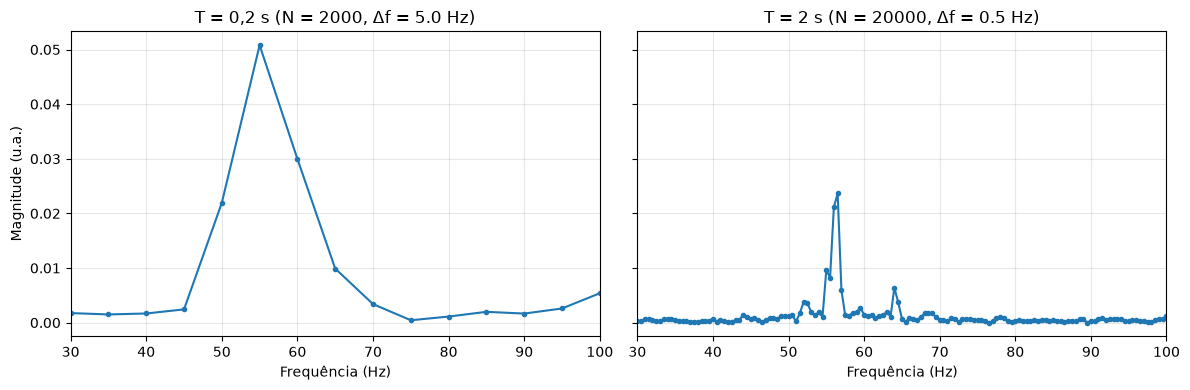

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (nome, (N, f_t, mag_t)) in zip(axs, res.items()):
    ax.plot(f_t, mag_t, ".-")
    ax.set_xlim(30, 100)
    ax.set_xlabel("Frequência (Hz)")
    ax.set_title(f"T = {nome} (N = {N}, Δf = {FS / N:.1f} Hz)")
    ax.grid(alpha=0.3)
axs[0].set_ylabel("Magnitude (u.a.)")
plt.tight_layout()
plt.savefig("../results/figures/resolucao_espectral.png", dpi=150)
plt.show()

### O que se vê

- Com T = 0,2 s (Δf = 5 Hz), os dois picos viram **um só**, em 55 Hz. Com T = 2 s (Δf = 0,5 Hz) aparecem separados, em 56,5 e 64,0 Hz.
- O pico único do trecho curto é mais alto (0,051) que o maior pico de 2 s (0,024), provavelmente porque o pico largo reúne componentes vizinhas. 
- A frequência fica menos precisa: com bins de 5 Hz, o pico aparece em 55 Hz.

**Importância.** Δf = 1 / T define quais picos podem ser distinguidos. Separar `f1` dos vizinhos, ou medir diferenças de poucos hertz no pico principal entre condições, exige Δf bem menor que isso, e por isso as janelas são de 2 s (Δf = 0,5 Hz). Por outro lado, os 2 s entram como um bloco só: variações dentro dele não aparecem.

## Aliasing: reduzindo a taxa de amostragem

Uma componente de frequência f acima de fs/2 (Nyquist) não desaparece ao amostrar: ela aparece em **|f − k·fs|**, com k inteiro, a frequência mais próxima de zero, e o espectro não diz que é falsa.

Registro saudável `F0_SV0_SP2_C1_R1`, que tem energia acima de 300 Hz. A taxa cai de 10000 Hz para **625 Hz** (fator Q = 16), com Nyquist em **312,5 Hz**. A janela de 2 s passa de 20000 para 1250 amostras, então Δf continua 0,5 Hz. Dois caminhos:

- **sem filtro**: `x[::Q]`, só descarta amostras;
- **com filtro**: `decimate`, que aplica um passa-baixa (FIR, fase zero) antes de descartar.

In [ ]:
x = get_matriz_acc("F0_SV0_SP2_C1_R1.mat", list_janelas)[JAN]

# nova taxa: FS / 16 = 625 Hz, Nyquist = 312,5 Hz
Q = 16
fs2 = FS / Q

f0, mag0 = espectro(x, FS)
# sem filtro: só descarta amostras
f_sf, mag_sf = espectro(x[::Q], fs2)
# com filtro passa-baixa antes de descartar
f_cf, mag_cf = espectro(decimate(x, Q, ftype="fir", zero_phase=True), fs2)
mag0, mag_sf, mag_cf = mag0[0], mag_sf[0], mag_cf[0]

print(f"fs original = {FS} Hz | nova fs = {fs2:.0f} Hz | Nyquist novo = {fs2 / 2:.1f} Hz | "
      f"N = {len(x[::Q])} | Δf = {f_sf[1] - f_sf[0]:.1f} Hz")

fs original = 10000 Hz | nova fs = 625 Hz | Nyquist novo = 312.5 Hz | N = 1250 | Δf = 0.5 Hz


In [ ]:
# 5 maiores picos do espectro original acima do novo Nyquist
idx, _ = find_peaks(mag0, distance=10)
idx = idx[f0[idx] > fs2 / 2]
idx = np.sort(idx[np.argsort(mag0[idx])[::-1][:5]])

linhas = []
for i in idx:
    fr = f0[i]
    # frequência aparente: distância até o múltiplo de fs2 mais próximo
    fap = abs(fr - fs2 * round(fr / fs2))
    # maior magnitude a menos de 1 Hz da frequência aparente
    linhas.append({"f real (Hz)": fr, "mag real": mag0[i], "f aparente (Hz)": fap,
                   "mag sem filtro": mag_sf[abs(f_sf - fap) <= 1].max(),
                   "mag com filtro": mag_cf[abs(f_cf - fap) <= 1].max()})
tab = pd.DataFrame(linhas)
print(tab.round(4).to_string(index=False))

 f real (Hz)  mag real  f aparente (Hz)  mag sem filtro  mag com filtro
       395.0    0.0268            230.0          0.0264          0.0013
       489.0    0.0082            136.0          0.0101          0.0023
       494.0    0.0266            131.0          0.0334          0.0032
       590.0    0.0102             35.0          0.0105          0.0023
      1382.5    0.0077            132.5          0.0273          0.0021


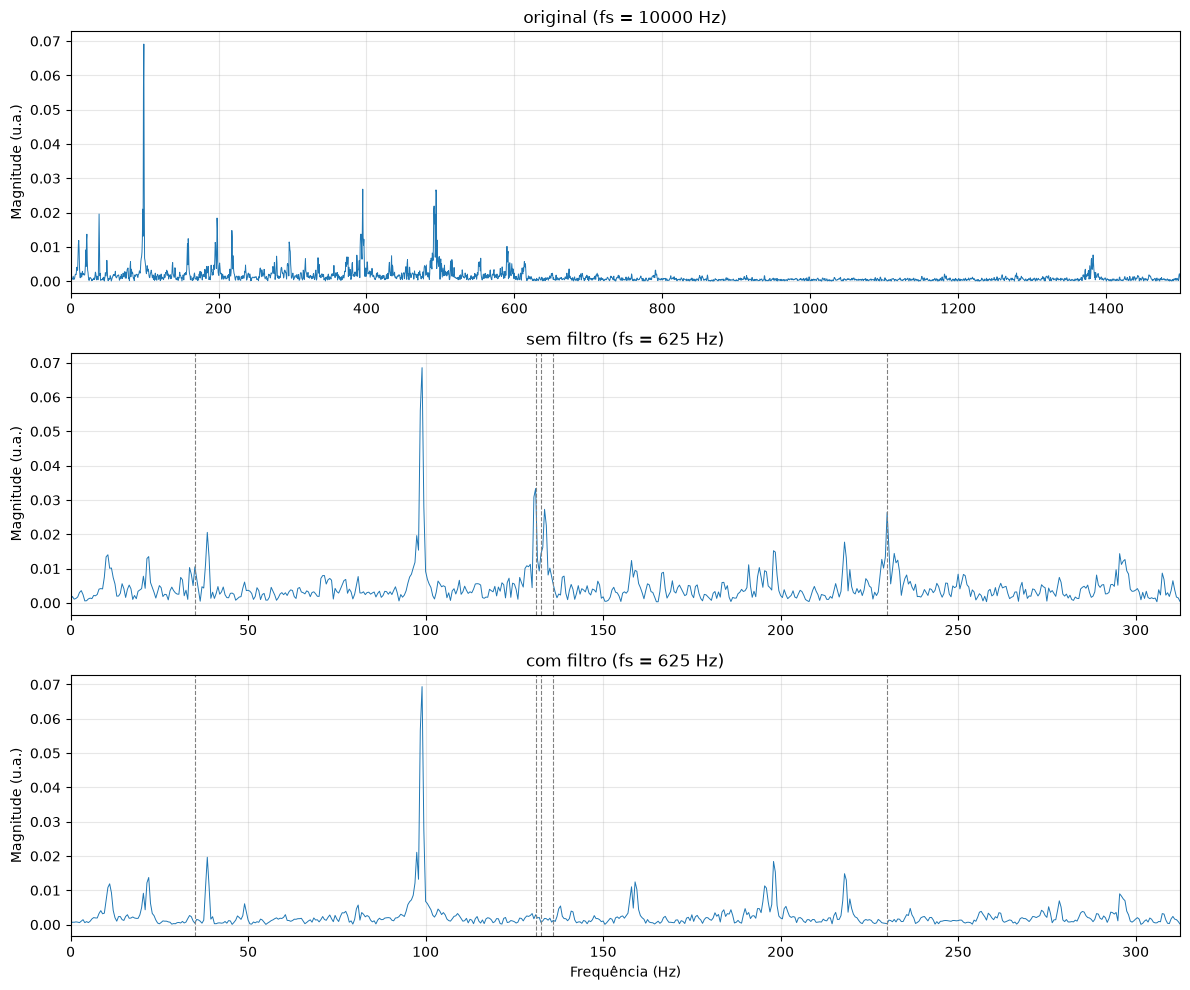

In [ ]:
fig, axs = plt.subplots(3, 1, figsize=(12, 10), sharey=True)
axs[0].plot(f0, mag0, lw=0.7)
axs[0].set_xlim(0, 1500)
axs[0].set_title(f"original (fs = {FS} Hz)")

for ax, (nome, f_x, mag_x) in zip(axs[1:], [("sem filtro", f_sf, mag_sf), ("com filtro", f_cf, mag_cf)]):
    ax.plot(f_x, mag_x, lw=0.7)
    # linhas tracejadas: frequências aparentes esperadas
    for fap in tab["f aparente (Hz)"]:
        ax.axvline(fap, ls="--", color="gray", lw=0.8)
    ax.set_xlim(0, fs2 / 2)
    ax.set_title(f"{nome} (fs = {fs2:.0f} Hz)")

for ax in axs:
    ax.set_ylabel("Magnitude (u.a.)")
    ax.grid(alpha=0.3)
axs[-1].set_xlabel("Frequência (Hz)")
plt.tight_layout()
plt.savefig("../results/figures/aliasing.png", dpi=150)
plt.show()

### O que se vê

- **Sem filtro**, aparecem picos que não existem no sinal, abaixo de 312,5 Hz, exatamente onde a fórmula prevê (linhas tracejadas): 395 Hz vira 230 Hz e 494 Hz vira 131 Hz. A magnitude se mantém (0,0264 em 230 Hz, contra 0,0268 do pico real), e o espectro não indica que são falsos.
- Duas frequências bem diferentes, 494 e 1382,5 Hz, caem perto da mesma frequência aparente (131 e 132,5 Hz): depois de amostrar, não dá para saber qual é qual.
- O patamar de ruído entre os picos também sobe sem filtro, porque o ruído acima de 312,5 Hz dobra para dentro da faixa.
- **Com filtro**, os picos abaixo do Nyquist (38,5, 99, 198 e 218 Hz) ficam como no original e os falsos somem: em 230 Hz a magnitude cai de 0,0264 para 0,0013.
